# XRD EDA & Pre-processing
This notebook is for exploratory data analysis and data splits of X-ray diffraction data.

Data source:

- PowCod
- COD
- ICSD
- CCDC
- Materials
- JARVIS


## Imports

In [ ]:
from functools import partial
from netrc import netrc
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import Sequential, Linear, ReLU, GRU

from torch.optim import Adam
from torch.nn import CrossEntropyLoss
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt

# Import the library to mount Google Drive
from google.colab import drive

import h5py

In [ ]:
# Mount the Google Drive at /content/drive
drive.mount('/content/drive')

Mounted at /content/drive


## Global Variables

In [ ]:
datasource = "PowCOD"
size = "small"
intensity_points = 500
twotheta = True
space = "2theta"
twotheta_start = 4.0
twotheta_end = 44.0
test_split = 0.20
validation_split = 0.20
path_X = '/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - Filter-PowCod-Run-1/4-44-CuKa1-data_4000_intensities.npy'
path_y = '/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - Filter-PowCod-Run-1/4-44-CuKa1-data_4000_space_group_number.npy'
data_path = '/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data/'



## Functions

In [ ]:
def convert_to_q_space(two_theta_deg, wavelength=1.5406):
    """
    Converts 2θ (degrees) to Q space (reciprocal space).

    Parameters:
    two_theta_deg (array-like): Array of 2θ values in degrees.
    wavelength (float): Wavelength of the X-ray in Ångströms (default is 1.5406 Å for Cu Kα radiation).

    Returns:
    np.ndarray: Corresponding Q values in reciprocal space.
    """
    # Convert 2θ to θ in radians
    two_theta_rad = np.deg2rad(two_theta_deg) / 2

    # Calculate Q values
    Q = (4 * np.pi * np.sin(two_theta_rad)) / wavelength

    return Q

## EDA

In [ ]:
X = np.load(path_X)
y = np.load(path_y)

In [ ]:
y = y.reshape(-1,1)

In [ ]:
Xy_concat = np.hstack((y, X))
Xy_concat

array([[2.00000000e+00, 1.00000000e+03, 2.93781708e+02, ...,
        6.04900002e-01, 8.88300002e-01, 5.14020014e+00],
       [4.00000000e+00, 3.44517487e+02, 1.36663803e+02, ...,
        2.87910008e+00, 1.08130002e+00, 2.67999992e-02],
       [1.40000000e+01, 4.80841095e+02, 1.00000000e+03, ...,
        7.72000030e-02, 2.87549996e+00, 0.00000000e+00],
       ...,
       [4.00000000e+00, 1.00000000e+03, 6.26381989e+01, ...,
        8.05400014e-01, 2.09540009e+00, 0.00000000e+00],
       [1.21000000e+02, 4.35793701e+02, 1.00000000e+03, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [3.30000000e+01, 8.84735413e+02, 2.07638596e+02, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00]])

In [ ]:
Xy_concat.shape

(288123, 501)

In [ ]:
df_describe = pd.DataFrame(Xy_concat)
df_describe.describe()

,0,1,2,3,4,5,6,7,8,9,...,491,492,493,494,495,496,497,498,499,500
count,288123.000000,288123.000000,288123.000000,288123.000000,288123.000000,288123.000000,288123.000000,288123.000000,288123.000000,288123.000000,...,288123.000000,288123.000000,288123.000000,288123.000000,288123.000000,288123.000000,288123.000000,288123.000000,288123.000000,288123.000000
mean,23.272384,352.622270,311.042263,287.446169,259.830361,240.489075,221.634783,206.001953,192.918288,179.600834,...,2.161015,2.145567,2.140258,2.143435,2.137153,2.106811,2.084953,1.995873,1.718335,1.061153
std,37.387276,376.180591,343.554159,327.930184,308.401488,294.042085,279.472097,264.611897,256.164171,244.194674,...,4.357877,4.315654,4.482867,4.311582,4.281382,4.276483,4.278468,4.413863,3.919174,3.251952
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.000000,27.723350,27.841100,25.581700,23.013600,20.833750,18.781450,17.682450,16.285700,14.832200,...,0.095100,0.091900,0.091900,0.091700,0.089700,0.083600,0.071200,0.039000,0.000000,0.000000
50%,14.000000,178.848404,159.195602,141.584000,122.945000,109.835197,98.437599,90.894203,82.232201,74.482803,...,0.625600,0.615400,0.617600,0.614700,0.609400,0.595900,0.563700,0.492800,0.271300,0.000000
75%,15.000000,658.222778,514.960205,455.706055,393.419800,354.689545,317.621155,290.765045,263.505554,240.910248,...,2.324600,2.310500,2.305350,2.313000,2.297350,2.269050,2.219500,2.097550,1.670700,0.581050
max,230.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,...,177.284302,195.423996,812.862610,210.091904,266.498505,369.505310,231.078995,707.965088,187.972504,172.492096


### Class Distribution

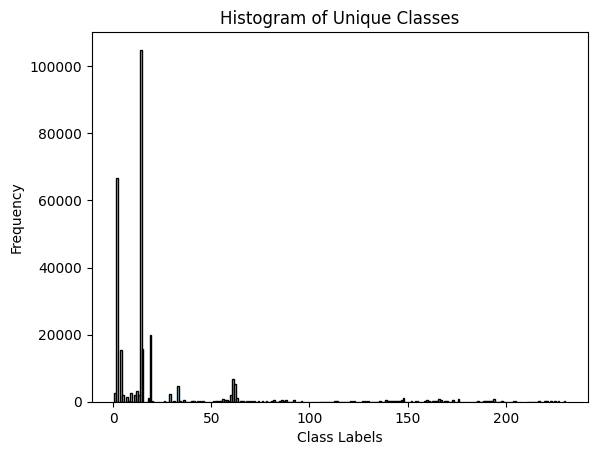

In [ ]:
# class distribution

# Count occurrences of values in the first column
unique_values, counts = np.unique(Xy_concat[:, 0], return_counts=True)

# Count unique classes
unique_classes, counts = np.unique(y, return_counts=True)


# Plot histogram
plt.bar(unique_classes, counts, color='skyblue', edgecolor='black')
plt.xlabel("Class Labels")
plt.ylabel("Frequency")
plt.title("Histogram of Unique Classes")
plt.show()



In [ ]:

# Sort classes by frequency (descending order)
sorted_indices = np.argsort(-counts)  # Negative sign to sort descending
sorted_classes = unique_classes[sorted_indices]
sorted_counts = counts[sorted_indices]

# Print sorted classes with counts
for cls, count in zip(sorted_classes, sorted_counts):
    print(f"Class: {cls}, Count: {count}")

Class: 14, Count: 104920
Class: 2, Count: 66559
Class: 19, Count: 20026
Class: 15, Count: 15737
Class: 4, Count: 15513
Class: 61, Count: 6896
Class: 62, Count: 5283
Class: 33, Count: 4564
Class: 12, Count: 3262
Class: 9, Count: 2680
Class: 1, Count: 2535
Class: 29, Count: 2262
Class: 60, Count: 2141
Class: 13, Count: 2102
Class: 5, Count: 2045
Class: 11, Count: 1952
Class: 7, Count: 1496
Class: 18, Count: 1200
Class: 63, Count: 1071
Class: 148, Count: 984
Class: 176, Count: 907
Class: 166, Count: 853
Class: 56, Count: 830
Class: 194, Count: 664
Class: 36, Count: 644
Class: 173, Count: 513
Class: 147, Count: 443
Class: 139, Count: 441
Class: 167, Count: 437
Class: 160, Count: 436
Class: 58, Count: 426
Class: 88, Count: 410
Class: 92, Count: 406
Class: 82, Count: 402
Class: 57, Count: 396
Class: 86, Count: 367
Class: 55, Count: 359
Class: 20, Count: 348
Class: 96, Count: 347
Class: 43, Count: 347
Class: 52, Count: 342
Class: 87, Count: 313
Class: 140, Count: 308
Class: 74, Count: 302
Cla

### Average XRD Pattern

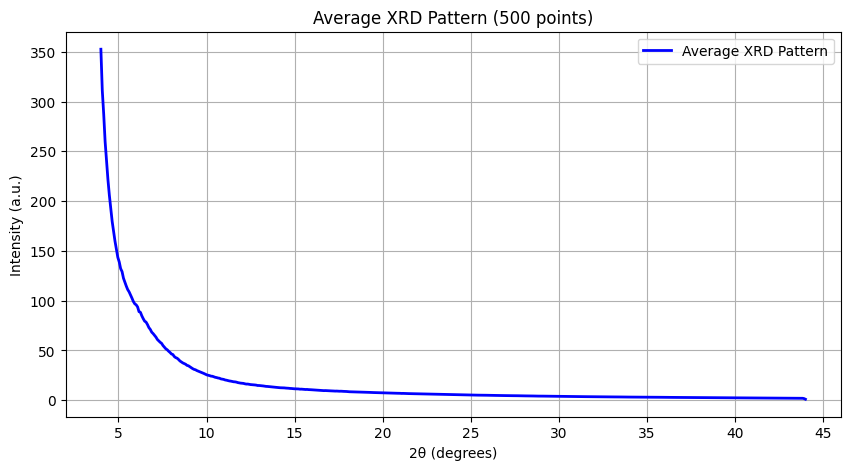

In [ ]:

# Compute the average XRD pattern
avg_xrd = np.mean(X, axis=0)
two_theta = np.linspace(4, 44, 500)  # 2θ range from 4 to 44° with 500 points

# Plot the average XRD pattern with 2θ on x-axis
plt.figure(figsize=(10, 5))
plt.plot(two_theta, avg_xrd, label="Average XRD Pattern", color="blue", linewidth=2)

plt.xlabel("2θ (degrees)")
plt.ylabel("Intensity (a.u.)")
plt.title("Average XRD Pattern (500 points)")
plt.legend()
plt.grid(True)
plt.show()


### Distribution of Intensities

In [ ]:
# Distribution of Intensities

In [ ]:
flattened_intensities = X.flatten()

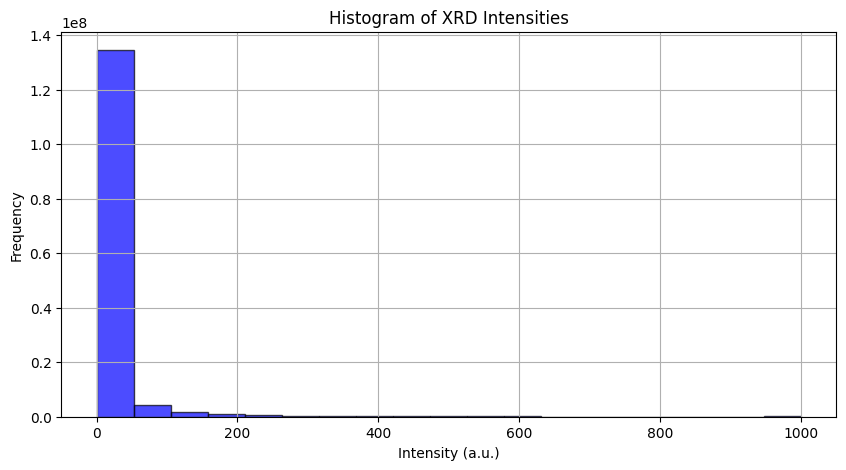

In [ ]:

# Plot histogram of intensities
plt.figure(figsize=(10, 5))

# bins = log2(288123) + 1

plt.hist(flattened_intensities, bins=19, color='blue', alpha=0.7, edgecolor='black')

plt.xlabel("Intensity (a.u.)")
plt.ylabel("Frequency")
plt.title("Histogram of XRD Intensities")
plt.grid(True)
plt.show()

## Pre-processing  

In [ ]:
# optional peak reduction, noise filtering, and dropping of single sample classes for proper training

In [ ]:
Xy_concat.shape

(288123, 501)

In [ ]:
# optional conversion to Q space

if twotheta == False:
  X = convert_to_q_space(X)

In [ ]:
# Count occurrences of values in the first column
unique_values, counts = np.unique(Xy_concat[:, 0], return_counts=True)

# Find values appearing at least twice
valid_values = unique_values[counts >= 2]

# Filter rows where the first column contains only valid values
filtered_arr = Xy_concat[np.isin(Xy_concat[:, 0], valid_values)]

print(filtered_arr.shape)  # New shape after filtering

(288121, 501)


## Data Splits

In [ ]:
y1 = filtered_arr[:, 0]
X1 = filtered_arr[:, 1:]

In [ ]:
y1.shape

(288121,)

In [ ]:
y1.shape

(288121,)

In [ ]:
X1.shape

(288121, 500)

In [ ]:
# COD is already converted to international space group numbers, use below code if space group is not encoded
#label_encoder = LabelEncoder()
#y1 = label_encoder.fit_transform(y1)

In [ ]:

X1 = torch.tensor(X1, dtype=torch.float)
y1 = torch.tensor(y1, dtype=torch.long)

# First split: Train/Test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X1, y1, test_size=0.2, random_state=42, stratify=y1)

# Second split: Train/Validation (80/20 of the original training set)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

# # Save to HDF5
# with h5py.File(output_path + f"{datasource}_{intensity_points}_{space}_{twotheta_start}_{twotheta_end}_{test_split}_{validation_split}.h5", "w") as f:
#     f.create_dataset("X_train", data=X_train)
#     f.create_dataset("y_train", data=y_train)
#     f.create_dataset("X_val", data=X_val)
#     f.create_dataset("y_val", data=y_val)
#     f.create_dataset("X_test", data=X_test)
#     f.create_dataset("y_test", data=y_test)

#save_path = "/content/drive/My Drive/dataset.h5"

with h5py.File(f"{data_path}{datasource}_{size}_{intensity_points}_{space}_{twotheta_start}_{twotheta_end}_{test_split}_{validation_split}.h5", "w") as f:
    f.create_dataset("X_train", data=X_train)
    f.create_dataset("y_train", data=y_train)
    f.create_dataset("X_val", data=X_val)
    f.create_dataset("y_val", data=y_val)
    f.create_dataset("X_test", data=X_test)
    f.create_dataset("y_test", data=y_test)

print(f"Data successfully split and saved to {data_path}{datasource}_{size}_{intensity_points}_{space}_{twotheta_start}_{twotheta_end}_{test_split}_{validation_split}.h5")

<ipython-input-28-0eaf58a7dced>:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X1 = torch.tensor(X1, dtype=torch.float)
<ipython-input-28-0eaf58a7dced>:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y1 = torch.tensor(y1, dtype=torch.long)


Data successfully split and saved to /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data/PowCOD_small_500_2theta_4.0_44.0_0.2_0.2.h5
